In [15]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline

m_dig = np.random.choice([1,2,3,4, 5])
p_dig = np.random.choice([2,3,4,5,6, 7])
t_dig = np.random.choice([8,9,10,11,12,13,14,15,16,17,18, 19])

m = m_dig / 100.0
p = p_dig / 10.0
t = t_dig / 100.0

t_str = str(t_dig) if t_dig >= 10 else "0" + str(t_dig)
naca = str(m_dig) + str(p_dig) + t_str

print("airfoil:", naca)

airfoil: 5308


In [16]:
def naca_airfoil(x, m, p, t):
    yt = 5.0 * t * (0.2969 * np.sqrt(x) - 0.1260 * x - 0.3516 * x**2 + 0.2843 * x**3 - 0.1015 * x**4)

    yc = np.zeros_like(x)
    dyc = np.zeros_like(x)
    
    for i in range(len(x)):
        xv = x[i]
        if xv < p:
            yc[i] = (m / (p ** 2)) * (2.0 * p * xv - xv ** 2)
            dyc[i] = (2.0 * m / (p ** 2)) * (p - xv)
        else:
            yc[i] = (m / ((1.0 - p) ** 2)) * ((1.0 - 2.0 * p) + 2.0 * p * xv - xv ** 2)
            dyc[i] = (2.0 * m / ((1.0 - p) ** 2)) * (p - xv)

    theta = np.arctan(dyc)
    xu = x - yt * np.sin(theta)
    yu = yc + yt * np.cos(theta)
    xl = x + yt * np.sin(theta)
    yl = yc - yt * np.cos(theta)

    return xu, yu, xl, yl

In [17]:
x_exact = np.linspace(0, 1, 500)

xu, yu, xl, yl = naca_airfoil(x_exact, m, p, t)

def lagrange(x, y, xx):
    summation = np.zeros_like(xx, dtype=float)
    for i in range(len(x)):
        product = np.ones_like(xx, dtype=float)
        for j in range(len(x)):
            if i != j:
                product *= (xx - x[j]) / (x[i] - x[j])

        summation += y[i] * product

    return summation


In [18]:
def error_calc(actual, approx):

    error = actual - approx
    max_error = np.max(np.abs(error))
    rms_error = np.sqrt(np.mean(error**2))
    return max_error, rms_error

N = 11
xx = np.linspace(0, 1, 500)

_, upper_true, _, lower_true = naca_airfoil(xx, m, p, t)

results = {}
curves = {}

In [19]:
for spacing in ["Uniform", "Cosine"]:

    if spacing == "Uniform":
        x = np.linspace(0, 1, N)

    else:
        beta = np.linspace(0, np.pi, N)
        x = (1-np.cos(beta))/2

    _, upper, _, lower = naca_airfoil(x, m, p, t)

    upper_lag = lagrange(x, upper, xx)
    lower_lag = lagrange(x, lower, xx)
    upper_cs = CubicSpline(x, upper)
    lower_cs = CubicSpline(x, lower)

    upper_spline = upper_cs(xx)
    lower_spline = lower_cs(xx)
    max1, rms1 = error_calc(upper_true, upper_lag)
    max2, rms2 = error_calc(lower_true, lower_lag)
    max3, rms3 = error_calc(upper_true, upper_spline)
    max4, rms4 = error_calc(lower_true, lower_spline)

    results[spacing] = [max(max1, max2),np.sqrt((rms1**2+rms2**2)/2),max(max3, max4),np.sqrt((rms3**2+rms4**2)/2)]
    curves[spacing] = [x, upper, lower,upper_lag, lower_lag,upper_spline, lower_spline]


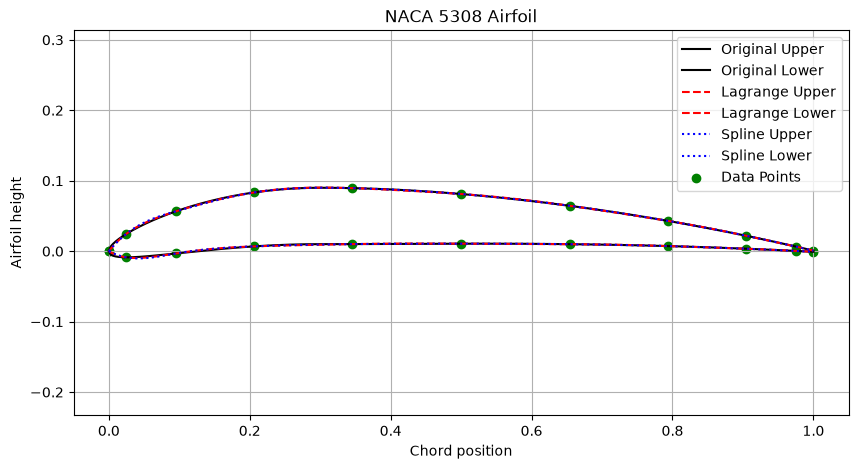


Error Comparison
-----------------------------------------------
Spacing    Lag Max    Lag RMS    Spline Max    Spline RMS
Uniform 0.0060001 0.0009309 0.00629 0.0012364
Cosine 0.0033723 0.0005847 0.0035772 0.0006781


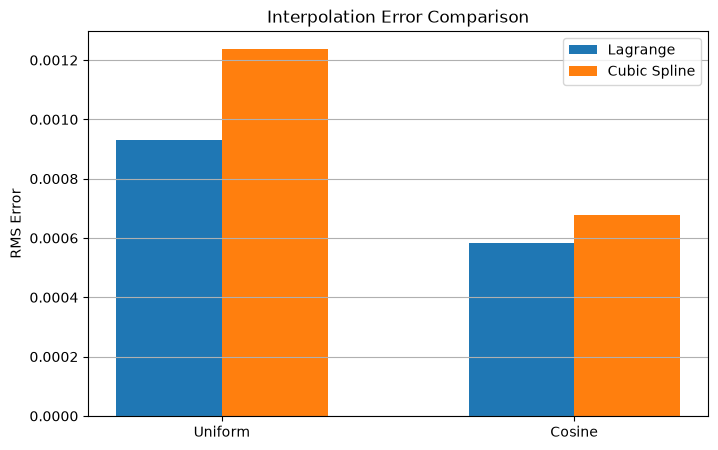

In [20]:
x, upper, lower, upper_lag, lower_lag, upper_spline, lower_spline = curves["Cosine"]

plt.figure(figsize=(10, 5))

plt.plot(xx, upper_true, 'k', label="Original Upper")
plt.plot(xx, lower_true, 'k', label="Original Lower")

plt.plot(xx, upper_lag, 'r--', label="Lagrange Upper")
plt.plot(xx, lower_lag, 'r--', label="Lagrange Lower")

plt.plot(xx, upper_spline, 'b:', label="Spline Upper")
plt.plot(xx, lower_spline, 'b:', label="Spline Lower")

plt.scatter(x, upper, color='green', label="Data Points")
plt.scatter(x, lower, color='green')

plt.xlabel("Chord position")
plt.ylabel("Airfoil height")
plt.title("NACA " + naca + " Airfoil")

plt.axis("equal")
plt.grid()
plt.legend()
plt.show()

print("\nError Comparison")
print("-----------------------------------------------")

print("Spacing    Lag Max    Lag RMS    Spline Max    Spline RMS")

for name in results:

    values = results[name]

    print(name,
          *[round(v, 7) for v in values])

names = ["Uniform", "Cosine"]

lag_errors = [results[s][1] for s in names]
spline_errors = [results[s][3] for s in names]

pos = np.arange(2)
width = 0.3

plt.figure(figsize=(8, 5))

plt.bar(pos-width/2, lag_errors, width, label="Lagrange")
plt.bar(pos+width/2, spline_errors, width, label="Cubic Spline")

plt.xticks(pos, names)
plt.ylabel("RMS Error")
plt.title("Interpolation Error Comparison")

plt.legend()
plt.grid(axis='y')
plt.show()
